# E2 — Method comparison (MNIST)

Vault: `Experiments/MNIST/E2 Method comparison`. Goal: rank the nine methods on the same footing and say what each preserves.

**Protocol** (`nldr.protocol`, see `00 Experiment overview`):

- **Track B, in-sample, all methods.** For every configuration of the grid: fit on $X_{\mathrm{val}}$ and score $\mathcal J = \mathrm{AUC}_{\log}(R_{NX})$ on it. Pick the best, fit it on the independent $X_{\mathrm{te}}$, and report every criterion there.
- **Track A, out-of-sample, methods with a map.** Fit on $X_{\mathrm{tr}}$, embed $X_{\mathrm{val}}$ with the learned map, select by $\mathcal J^{\mathrm{oos}}$, then embed $X_{\mathrm{te}}$ with the same map and report. t-SNE has no map and is excluded.

Grids come from `nldr/config.py`. Every embedding is cached in `results/embeddings/`, so re-running only computes what is missing, and adding splits later reuses the earlier ones.

**Run plan.** First pass: `Q = 2`, `SPLITS = [0]` (figures for the presentation, about 10–15 minutes). Then `SPLITS = config.SPLIT_SEEDS` for mean ± s.d., and finally `Q = 10` for the tables (slow: t-SNE needs its exact algorithm above 3 dimensions).

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # make the nldr package importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nldr import config, data, metrics, methods, plotting, protocol

config.RESULTS_DIR.mkdir(exist_ok=True)
config.FIGURES_DIR.mkdir(exist_ok=True)

## 0. Settings for this run

In [2]:
Q = config.Q_FIGURES                 # 2 for figures; config.Q_TABLES (= 10) for the tables
SPLITS = [0]                         # quick first pass; config.SPLIT_SEEDS for mean ± s.d.
METHODS = ["pca", "kpca", "mds", "isomap", "lle", "le", "tsne", "umap", "ae"]
FIT_KWARGS = {"ae": {"epochs": 100}}
NAMES = {"pca": "PCA", "kpca": "Kernel PCA", "mds": "Classical MDS", "isomap": "Isomap",
         "lle": "LLE", "le": "Laplacian eigenmaps", "tsne": "t-SNE", "umap": "UMAP", "ae": "Autoencoder"}
if Q > 3 and "tsne" in METHODS:
    print("Note: t-SNE with q > 3 uses the exact O(n^2) algorithm and takes several minutes per run.")

In [3]:
import time, warnings
X, y = data.load_mnist()
splits = [s for s in data.make_splits() if s.seed in SPLITS]
rho = {s.seed: {"val": metrics.rank_matrix(X[s.val]), "te": metrics.rank_matrix(X[s.te])} for s in splits}
print(f"{len(splits)} split(s), n = {config.N_PER_SPLIT} per sample, q = {Q}")

1 split(s), n = 2000 per sample, q = 2


## 1. Track B: in-sample, all methods

Selection by $\mathcal J$ on $X_{\mathrm{val}}$, report on $X_{\mathrm{te}}$. Progress is printed per method; cached runs are instant.

In [4]:
rows_b = []
for s in splits:
    for m in METHODS:
        t0 = time.perf_counter()
        r = protocol.track_b(m, X, y, s, Q, rho[s.seed]["val"], rho[s.seed]["te"],
                             fit_kwargs=FIT_KWARGS.get(m))
        rows_b.append(r)
        status = "all configurations failed" if r is None else f"J = {r['J']:.3f}  [{r['params']}]"
        print(f"split {s.seed}  {NAMES[m]:<20} {status}   ({time.perf_counter() - t0:.0f} s)")
rows_b = [r for r in rows_b if r is not None]
table_b = protocol.to_table(rows_b)
table_b.to_csv(config.RESULTS_DIR / f"E2_trackB_q{Q}.csv", index=False)

split 0  PCA                  J = 0.161  [-]   (2 s)
split 0  Kernel PCA           J = 0.162  [kernel=poly, degree=2]   (6 s)
split 0  Classical MDS        J = 0.161  [-]   (3 s)
split 0  Isomap               J = 0.175  [n_neighbors=20]   (13 s)
split 0  LLE                  J = 0.193  [n_neighbors=5, reg=0.1]   (7 s)
split 0  Laplacian eigenmaps  J = 0.196  [n_neighbors=5, tau_factor=1.0]   (7 s)
split 0  t-SNE                J = 0.453  [perplexity=15]   (15 s)


/opt/anaconda3/envs/nldr/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


split 0  UMAP                 J = 0.351  [n_neighbors=5, min_dist=0.0]   (25 s)
split 0  Autoencoder          J = 0.285  [hidden=(1000, 500, 250), weight_decay=0.0]   (97 s)


### Table 1 (Track B): mean ± s.d. over splits

$\mathcal J$, trustworthiness and continuity at $K = 10$, Spearman correlation of distances, class-centroid correlation, $k$-NN accuracy, silhouette, ARI, and the time of the final fit.

In [5]:
cols = ["J", "T10", "C10", "spearman", "centroid_corr", "knn_acc", "silhouette", "ari", "seconds"]
summary_b = protocol.summarise(table_b, cols, order=METHODS).rename(index=NAMES)
summary_b.to_csv(config.RESULTS_DIR / f"E2_trackB_q{Q}_summary.csv")
summary_b

,n_splits,J,T10,C10,spearman,centroid_corr,knn_acc,silhouette,ari,seconds
method,,,,,,,,,,
PCA,1,0.161 ± 0.0,0.734 ± 0.0,0.905 ± 0.0,0.49 ± 0.0,0.851 ± 0.0,0.411 ± 0.0,0.015 ± 0.0,0.234 ± 0.0,0.277 ± 0.0
Kernel PCA,1,0.162 ± 0.0,0.732 ± 0.0,0.904 ± 0.0,0.499 ± 0.0,0.856 ± 0.0,0.395 ± 0.0,0.014 ± 0.0,0.236 ± 0.0,0.249 ± 0.0
Classical MDS,1,0.161 ± 0.0,0.734 ± 0.0,0.905 ± 0.0,0.49 ± 0.0,0.851 ± 0.0,0.411 ± 0.0,0.015 ± 0.0,0.234 ± 0.0,1.099 ± 0.0
Isomap,1,0.175 ± 0.0,0.754 ± 0.0,0.928 ± 0.0,0.546 ± 0.0,0.717 ± 0.0,0.433 ± 0.0,-0.035 ± 0.0,0.219 ± 0.0,1.845 ± 0.0
LLE,1,0.193 ± 0.0,0.806 ± 0.0,0.921 ± 0.0,0.26 ± 0.0,0.734 ± 0.0,0.715 ± 0.0,0.094 ± 0.0,0.391 ± 0.0,0.478 ± 0.0
Laplacian eigenmaps,1,0.196 ± 0.0,0.811 ± 0.0,0.933 ± 0.0,0.35 ± 0.0,0.857 ± 0.0,0.679 ± 0.0,0.124 ± 0.0,0.335 ± 0.0,0.475 ± 0.0
t-SNE,1,0.453 ± 0.0,0.971 ± 0.0,0.948 ± 0.0,0.397 ± 0.0,0.701 ± 0.0,0.906 ± 0.0,0.191 ± 0.0,0.464 ± 0.0,2.115 ± 0.0
UMAP,1,0.351 ± 0.0,0.959 ± 0.0,0.941 ± 0.0,0.311 ± 0.0,0.633 ± 0.0,0.888 ± 0.0,0.288 ± 0.0,0.569 ± 0.0,1.197 ± 0.0
Autoencoder,1,0.285 ± 0.0,0.95 ± 0.0,0.916 ± 0.0,0.384 ± 0.0,0.719 ± 0.0,0.78 ± 0.0,0.001 ± 0.0,0.284 ± 0.0,21.548 ± 0.0


### Selected hyperparameters (per split)

In [6]:
table_b.pivot(index="method", columns="split", values="params").reindex(METHODS).rename(index=NAMES)

split,0
method,
PCA,-
Kernel PCA,"kernel=poly, degree=2"
Classical MDS,-
Isomap,n_neighbors=20
LLE,"n_neighbors=5, reg=0.1"
Laplacian eigenmaps,"n_neighbors=5, tau_factor=1.0"
t-SNE,perplexity=15
UMAP,"n_neighbors=5, min_dist=0.0"
Autoencoder,"hidden=(1000, 500, 250), weight_decay=0.0"


### Figure 1: $R_{NX}(K)$ against $\log K$ (Track B)

Mean curve over the splits; the legend gives $\mathcal J$. Read the left part as fine within-class structure, $K\approx 200$ (the class size at $n = 2000$) as whole classes, and the right part as the arrangement of classes.

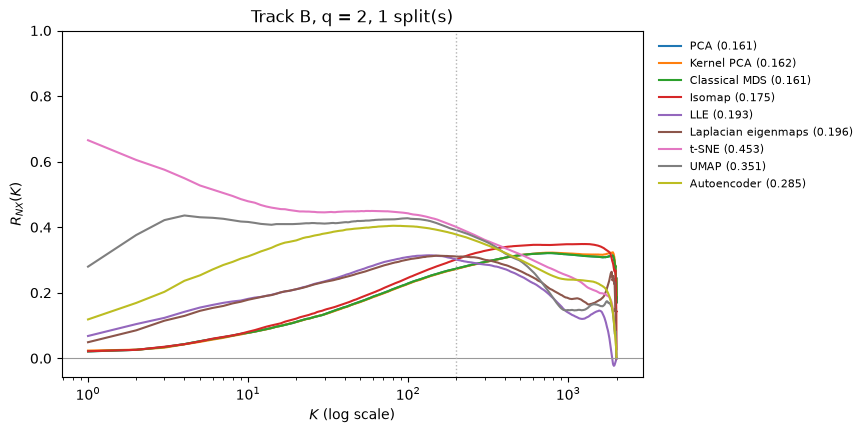

In [7]:
curves = {}
for m in METHODS:
    rs = [r["rnx"] for r in rows_b if r["method"] == m]
    if rs:
        mean = np.mean(rs, axis=0)
        curves[NAMES[m]] = (mean, metrics.auc_log(mean))
fig, ax = plt.subplots(figsize=(7.5, 4.5))
plotting.rnx_curves(curves, ax=ax, title=f"Track B, q = {Q}, {len(splits)} split(s)")
ax.axvline(config.N_PER_SPLIT / 10, color="0.7", ls=":", lw=1)
plotting.save(fig, f"E2_rnx_trackB_q{Q}"); plt.show()

### Figure 2: the embeddings of $X_{\mathrm{te}}$ (first split, coloured by digit)

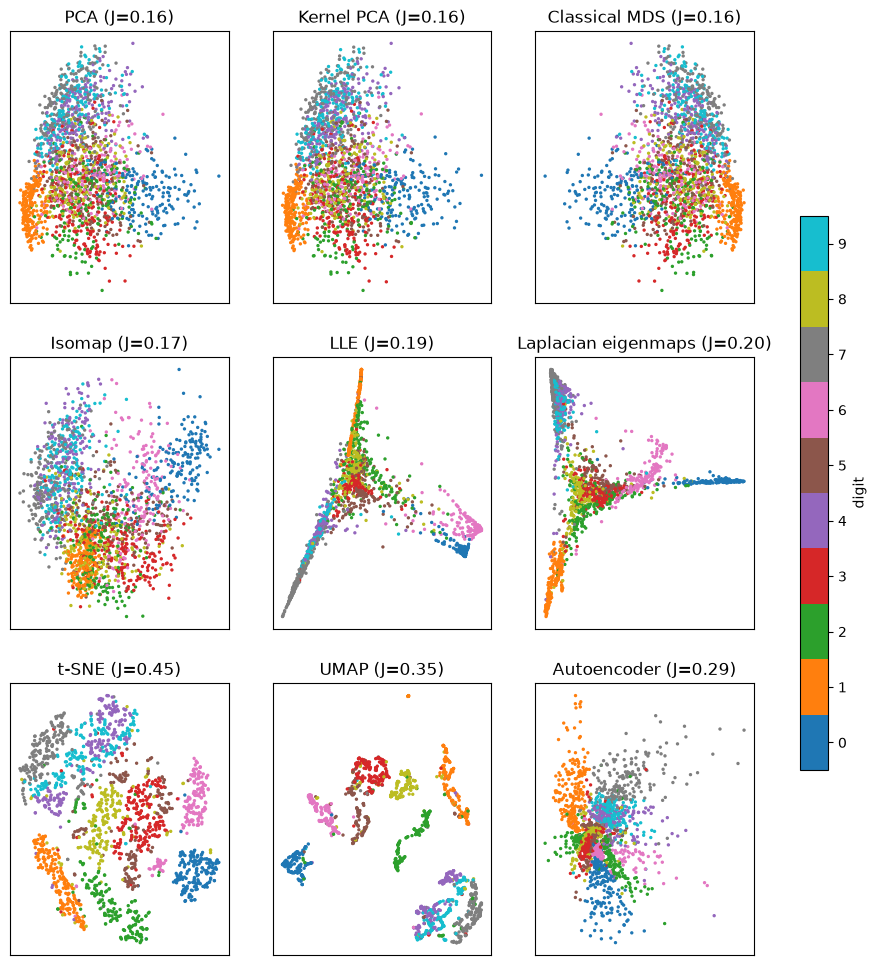

In [8]:
if Q == 2:
    s0 = splits[0].seed
    embs = {f"{NAMES[r['method']]} (J={r['J']:.2f})": r["Y"] for m in METHODS
            for r in rows_b if r["method"] == m and r["split"] == s0}
    fig = plotting.embedding_grid(embs, y[splits[0].te], ncols=3)
    plotting.save(fig, "E2_embeddings_q2"); plt.show()
else:
    print("Embedding grid only for q = 2.")

## 2. Track A: out-of-sample, methods with a map

Fit on $X_{\mathrm{tr}}$; new points embedded by the learned map (exact for PCA, kernel PCA, autoencoder; Nyström or Gower for MDS, Isomap, LLE, Laplacian eigenmaps; approximate `transform` for UMAP). Out-of-sample $R_{NX}$ uses the training points as reference.

In [9]:
rows_a = []
for s in splits:
    for m in METHODS:
        if m in protocol.NO_MAP:
            continue
        t0 = time.perf_counter()
        r = protocol.track_a(m, X, y, s, Q, fit_kwargs=FIT_KWARGS.get(m))
        rows_a.append(r)
        status = "all configurations failed" if r is None else f"J_oos = {r['J_oos']:.3f}  [{r['params']}]"
        print(f"split {s.seed}  {NAMES[m]:<20} {status}   ({time.perf_counter() - t0:.0f} s)")
rows_a = [r for r in rows_a if r is not None]
table_a = protocol.to_table(rows_a)
table_a.to_csv(config.RESULTS_DIR / f"E2_trackA_q{Q}.csv", index=False)
summary_a = protocol.summarise(table_a, ["J_oos", "knn_acc_oos"], order=METHODS).rename(index=NAMES)
summary_a.to_csv(config.RESULTS_DIR / f"E2_trackA_q{Q}_summary.csv")
summary_a

split 0  PCA                  J_oos = 0.163  [-]   (2 s)
split 0  Kernel PCA           J_oos = 0.163  [kernel=rbf, sigma_factor=10.0]   (13 s)
split 0  Classical MDS        J_oos = 0.163  [-]   (4 s)
split 0  Isomap               J_oos = 0.186  [n_neighbors=10]   (18 s)
split 0  LLE                  J_oos = 0.174  [n_neighbors=10, reg=0.1]   (18 s)
split 0  Laplacian eigenmaps  J_oos = 0.202  [n_neighbors=5, tau_factor=1.0]   (15 s)
split 0  UMAP                 J_oos = 0.309  [n_neighbors=5, min_dist=0.1]   (83 s)
split 0  Autoencoder          J_oos = 0.242  [hidden=(1000, 500, 250), weight_decay=0.0]   (81 s)


,n_splits,J_oos,knn_acc_oos
method,,,
PCA,1,0.163 ± 0.0,0.422 ± 0.0
Kernel PCA,1,0.163 ± 0.0,0.42 ± 0.0
Classical MDS,1,0.163 ± 0.0,0.422 ± 0.0
Isomap,1,0.186 ± 0.0,0.5 ± 0.0
LLE,1,0.174 ± 0.0,0.69 ± 0.0
Laplacian eigenmaps,1,0.202 ± 0.0,0.713 ± 0.0
UMAP,1,0.309 ± 0.0,0.842 ± 0.0
Autoencoder,1,0.242 ± 0.0,0.676 ± 0.0


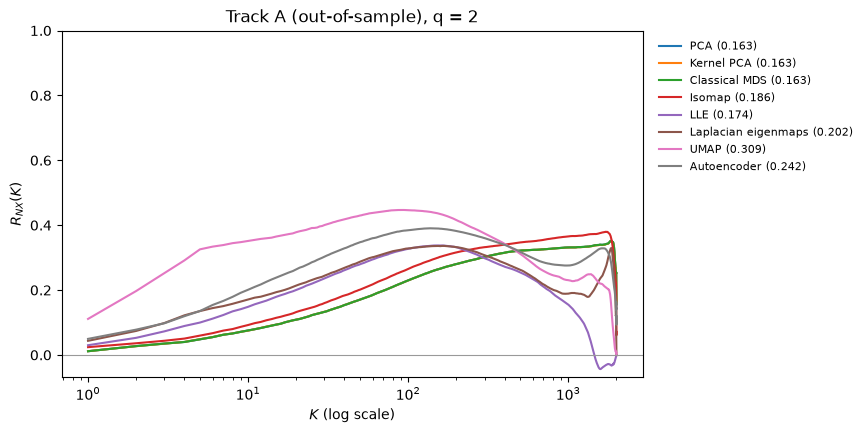

In [10]:
curves_a = {}
for m in METHODS:
    rs = [r["rnx_oos"] for r in rows_a if r["method"] == m]
    if rs:
        mean = np.mean(rs, axis=0)
        curves_a[NAMES[m]] = (mean, metrics.auc_log(mean))
fig, ax = plt.subplots(figsize=(7.5, 4.5))
plotting.rnx_curves(curves_a, ax=ax, title=f"Track A (out-of-sample), q = {Q}")
plotting.save(fig, f"E2_rnx_trackA_q{Q}"); plt.show()

## 3. Questions for the write-up

**(a) Which methods lose most on new points?** In-sample $\mathcal J$ (Track B) next to out-of-sample $\mathcal J^{\mathrm{oos}}$ (Track A). A large drop means the learned map generalises poorly (the overfitting question of E4).

In [11]:
gap = (table_b.groupby("method")["J"].mean().to_frame("J_in_sample (B)")
       .join(table_a.groupby("method")["J_oos"].mean().to_frame("J_out_of_sample (A)"), how="left"))
gap["drop"] = gap["J_in_sample (B)"] - gap["J_out_of_sample (A)"]
gap.reindex(METHODS).rename(index=NAMES).round(3)

,J_in_sample (B),J_out_of_sample (A),drop
method,,,
PCA,0.161,0.163,-0.002
Kernel PCA,0.162,0.163,-0.002
Classical MDS,0.161,0.163,-0.002
Isomap,0.175,0.186,-0.012
LLE,0.193,0.174,0.018
Laplacian eigenmaps,0.196,0.202,-0.006
t-SNE,0.453,NaN,NaN
UMAP,0.351,0.309,0.042
Autoencoder,0.285,0.242,0.044


**(b) Does the ranking depend on the $1/K$ weighting?** Rank the methods by $\mathcal J$ and by the plain (uniform) mean of $R_{NX}$, which is dominated by large $K$. A high rank correlation means the conclusion is robust to the weighting.

In [12]:
from scipy.stats import spearmanr
rank_df = pd.DataFrame({
    "J (1/K weights)": {NAMES[m]: np.mean([r["J"] for r in rows_b if r["method"] == m]) for m in METHODS
                        if any(r["method"] == m for r in rows_b)},
    "uniform mean of R_NX": {NAMES[m]: np.mean([r["rnx"].mean() for r in rows_b if r["method"] == m])
                             for m in METHODS if any(r["method"] == m for r in rows_b)},
})
rank_df["rank by J"] = rank_df.iloc[:, 0].rank(ascending=False).astype(int)
rank_df["rank uniform"] = rank_df.iloc[:, 1].rank(ascending=False).astype(int)
print(f"Spearman correlation of the two rankings: {spearmanr(rank_df.iloc[:, 0], rank_df.iloc[:, 1]).statistic:.2f}")
rank_df.sort_values("rank by J").round(3)

Spearman correlation of the two rankings: -0.56


,J (1/K weights),uniform mean of R_NX,rank by J,rank uniform
t-SNE,0.453,0.266,1,5
UMAP,0.351,0.220,2,8
Autoencoder,0.285,0.259,3,6
Laplacian eigenmaps,0.196,0.220,4,7
LLE,0.193,0.170,5,9
Isomap,0.175,0.324,6,1
Kernel PCA,0.162,0.303,7,2
PCA,0.161,0.300,8,3
Classical MDS,0.161,0.300,8,3


**(c) Local versus global versus classes.** Which method wins at each scale, and do $\mathcal J$ and $k$-NN accuracy agree?

In [13]:
n = config.N_PER_SPLIT
scales = {"K <= 20 (look-alikes)": slice(0, 20), f"K ~ {n // 10} (whole class)": slice(n // 20, n // 5),
          f"K >= {n // 4} (class layout)": slice(n // 4, None)}
scale_df = pd.DataFrame({lab: {name: c[0][sl].mean() for name, c in curves.items()} for lab, sl in scales.items()})
scale_df["knn_acc"] = table_b.groupby("method")["knn_acc"].mean().rename(index=NAMES)
print("Best method per scale:", {lab: scale_df[lab].idxmax() for lab in scales})
scale_df.round(3)

Best method per scale: {'K <= 20 (look-alikes)': 't-SNE', 'K ~ 200 (whole class)': 't-SNE', 'K >= 500 (class layout)': 'Isomap'}


,K <= 20 (look-alikes),K ~ 200 (whole class),K >= 500 (class layout),knn_acc
PCA,0.074,0.280,0.312,0.411
Kernel PCA,0.074,0.279,0.317,0.395
Classical MDS,0.074,0.280,0.312,0.411
Isomap,0.079,0.310,0.336,0.433
LLE,0.172,0.294,0.133,0.715
Laplacian eigenmaps,0.167,0.304,0.198,0.679
t-SNE,0.499,0.384,0.225,0.906
UMAP,0.407,0.375,0.170,0.888
Autoencoder,0.294,0.363,0.226,0.780


## 4. Summary for the results log

In [14]:
import datetime
print(f"### {datetime.date.today()} — E2 — method comparison, q = {Q}, splits {SPLITS}")
print(f"- Data: n = {config.N_PER_SPLIT} per sample; grids from nldr/config.py; seed 0 for non-convex methods")
print("- Track B (mean J, best first):",
      ", ".join(f"{k} {v:.3f}" for k, v in table_b.groupby('method')['J'].mean().rename(index=NAMES)
                .sort_values(ascending=False).items()))
print("- Track A (mean J_oos, best first):",
      ", ".join(f"{k} {v:.3f}" for k, v in table_a.groupby('method')['J_oos'].mean().rename(index=NAMES)
                .sort_values(ascending=False).items()))
print("- Figures: E2_rnx_trackB_q{0}, E2_rnx_trackA_q{0}".format(Q) + (", E2_embeddings_q2" if Q == 2 else ""))

### 2026-11-23 — E2 — method comparison, q = 2, splits [0]
- Data: n = 2000 per sample; grids from nldr/config.py; seed 0 for non-convex methods
- Track B (mean J, best first): t-SNE 0.453, UMAP 0.351, Autoencoder 0.285, Laplacian eigenmaps 0.196, LLE 0.193, Isomap 0.175, Kernel PCA 0.162, Classical MDS 0.161, PCA 0.161
- Track A (mean J_oos, best first): UMAP 0.309, Autoencoder 0.242, Laplacian eigenmaps 0.202, Isomap 0.186, LLE 0.174, Classical MDS 0.163, PCA 0.163, Kernel PCA 0.163
- Figures: E2_rnx_trackB_q2, E2_rnx_trackA_q2, E2_embeddings_q2
